# Study 6 ablations under the ZOIB linking: fitted length scale vs flat length scale

Two model families, β fitted wherever there is a speaker:

- **fitted ls**: the GP length scale is fitted (feature-space generalization).
- **flat ls**: the length scale is pinned at `LS_FLAT` (feature-independent generalization).

Each family gets the same ablations, shown as one row of the figure: **no transfer | literal semantics | full (pragmatic)**.
No transfer has no utterances, so the length scale does nothing and it is the same fit in both rows.

Fits (`run_parameter_estimation.py study6-zoib`):

| panel | fitted-ls row | flat-ls row |
|---|---|---|
| no transfer | `study6-ablations-zoib/posterior-notransfer.npz` | same |
| literal semantics | `study6-ablations-zoib/posterior-litsem.npz` | `study6-ablations-zoib/posterior-litsem-null.npz` |
| full | `study6-fit-zoib/posterior.npz` | `study6-fit-zoib/posterior-null.npz` |

Predictions are **ratings-free** (coherence inferred from the utterances only), as in `study6-ablations.ipynb`.
The ZOIB linking of each model is profiled at that model's posterior median.

In [1]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")
import sys
sys.path.insert(0, ".")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plot_style
plot_style.use_lexend()
import jax.numpy as jnp

import inference as inf
import linking as lk
import studies68 as s68

FULL_DIR = os.path.join('results', 'study6-fit-zoib')
ABL_DIR  = os.path.join('results', 'study6-ablations-zoib')

def load_geom(variant):
    g, r = s68.load_study6_prereg(clip_interior=False)          # RAW ratings for the ZOIB
    if variant == 'litsem':
        g['speaker'] = 'literal'
    elif variant == 'notransfer':
        for c in list(g['x_train_cond']):
            g['x_train_cond'][c] = jnp.zeros((0, 2))
            g['u_train_cond'][c] = jnp.zeros(0, dtype=jnp.int32)
            g['train_names_cond'][c] = []
    return g, r

geom, responses_cond = load_geom('full')
J, test_feature_names = geom['J'], geom['test_feature_names']
CONDS = list(geom['x_train_cond'])
emp_cond = {c: np.array(responses_cond[c]).mean(0) for c in CONDS}

def load_fit(path):
    z = np.load(path, allow_pickle=True)
    fit = {k: z[k] for k in ('ls_samples', 'mu0_samples', 'sigma_samples', 'beta_samples')}
    fit.update(json.loads(str(z['meta'])))
    return fit

# (family, ablation) -> fit file, geometry variant, number of free params
SPECS = {
    ('fitted ls', 'no transfer'):       (os.path.join(ABL_DIR, 'posterior-notransfer.npz'),  'notransfer', 2),
    ('fitted ls', 'literal semantics'): (os.path.join(ABL_DIR, 'posterior-litsem.npz'),      'litsem',     3),
    ('fitted ls', 'full (pragmatic)'):  (os.path.join(FULL_DIR, 'posterior.npz'),            'full',       4),
    ('flat ls',   'no transfer'):       (os.path.join(ABL_DIR, 'posterior-notransfer.npz'),  'notransfer', 2),
    ('flat ls',   'literal semantics'): (os.path.join(ABL_DIR, 'posterior-litsem-null.npz'), 'litsem',     2),
    ('flat ls',   'full (pragmatic)'):  (os.path.join(FULL_DIR, 'posterior-null.npz'),       'full',       3),
}
FAMILIES = ['fitted ls', 'flat ls']
ABLATIONS = ['no transfer', 'literal semantics', 'full (pragmatic)']
for key, (path, _, _) in SPECS.items():
    f = load_fit(path)
    print(f"{key[0]:<10}{key[1]:<19} {f['convergence_status']:<9} evals={f['func_count']:<4} ELBO={f['elbo']:.1f}")

load_study6_prereg: 446 of 471 rows kept after exclusions
fitted ls no transfer         probable  evals=105  ELBO=-1368.3
fitted ls literal semantics   probable  evals=130  ELBO=-1251.8
fitted ls full (pragmatic)    probable  evals=170  ELBO=-1254.8
flat ls   no transfer         probable  evals=105  ELBO=-1368.3
flat ls   literal semantics   probable  evals=115  ELBO=-1265.5
flat ls   full (pragmatic)    probable  evals=150  ELBO=-1268.8


## Forward passes and comparison table

In [2]:
results, cache = {}, {}
for key, (path, variant, k) in SPECS.items():
    if path in cache:                                  # no transfer: same fit in both families
        results[key] = cache[path]; continue
    f = load_fit(path)
    ls, mu, sig = (float(np.median(f['ls_samples'])), float(np.median(f['mu0_samples'])),
                   float(np.median(f['sigma_samples'])))
    beta = float(np.median(f['beta_samples']))
    beta_used = inf.BETA_SPEAKER if np.isnan(beta) else beta   # no speaker -> beta unused
    g, r = load_geom(variant)
    ll, link_theta, _ = inf.total_log_lik_zoib(g, r, ls, mu, sig, beta_speaker=beta_used, return_link=True)
    p = lk.unpack(jnp.asarray(link_theta))
    pz1 = inf.prior_pz1_modes(g, ls, mu, sig, beta_speaker=beta_used)
    pred = {c: np.asarray(lk.expected_rating(p, pz1[c])) for c in CONDS}
    allp = np.concatenate([pred[c] for c in CONDS]); alle = np.concatenate([emp_cond[c] for c in CONDS])
    results[key] = cache[path] = dict(theta=(ls, mu, sig, beta), ll=ll, elbo=f['elbo'], k=k, pred=pred,
                                      r2=np.corrcoef(allp, alle)[0, 1] ** 2)

table = pd.DataFrame([{'family': fam, 'model': ab, 'k': results[fam, ab]['k'],
                       'ls': results[fam, ab]['theta'][0], 'mu_0': results[fam, ab]['theta'][1],
                       'sigma': results[fam, ab]['theta'][2], 'beta': results[fam, ab]['theta'][3],
                       'ELBO': results[fam, ab]['elbo'], 'sum log Z': results[fam, ab]['ll'],
                       'r2 per feature': results[fam, ab]['r2'],
                       **{f'mean {c}': results[fam, ab]['pred'][c].mean() for c in CONDS}}
                      for fam in FAMILIES for ab in ABLATIONS]).set_index(['family', 'model'])
print('human condition means:', {c: round(float(emp_cond[c].mean()), 3) for c in CONDS})
table.round(3)

load_study6_prereg: 446 of 471 rows kept after exclusions


load_study6_prereg: 446 of 471 rows kept after exclusions


load_study6_prereg: 446 of 471 rows kept after exclusions


load_study6_prereg: 446 of 471 rows kept after exclusions


load_study6_prereg: 446 of 471 rows kept after exclusions


human condition means: {'generic': 0.515, 'specific': 0.289, 'baseline': 0.384}


k      ls   mu_0  sigma   beta      ELBO  \
family    model                                                         
fitted ls no transfer        2  10.000  0.392  2.290    NaN -1368.291   
          literal semantics  3   0.793 -0.457  0.669    NaN -1251.756   
          full (pragmatic)   4   0.766 -0.064  0.607  8.945 -1254.830   
flat ls   no transfer        2  10.000  0.392  2.290    NaN -1368.291   
          literal semantics  2  10.000 -0.397  0.625    NaN -1265.478   
          full (pragmatic)   3  10.000 -0.006  0.542  9.891 -1268.777   

                             sum log Z  r2 per feature  mean generic  \
family    model                                                        
fitted ls no transfer        -1368.114           0.404         0.397   
          literal semantics  -1248.454           0.812         0.500   
          full (pragmatic)   -1251.221           0.907         0.498   
flat ls   no transfer        -1368.114           0.404         0.397   
          literal semantics  -1262.369           0.817         0.498   
          full (pragmatic)   -1265.428           0.908         0.497   

                             mean specific  mean baseline  
family    model                                            
fitted ls no transfer                0.397          0.397  
          literal semantics          0.347          0.347  
          full (pragmatic)           0.291          0.402  
flat ls   no transfer                0.397          0.397  
          literal semantics          0.348          0.348  
          full (pragmatic)           0.292          0.403

## Figure: ablations in each family

Exp-1a slide format: x = model prevalence, y = human prevalence, small dots = condition x feature cells, large
dots = condition means. Top row = fitted length scale, bottom row = flat length scale.

saved results/study6-ablations-zoib/ablations-fitted-ls.png


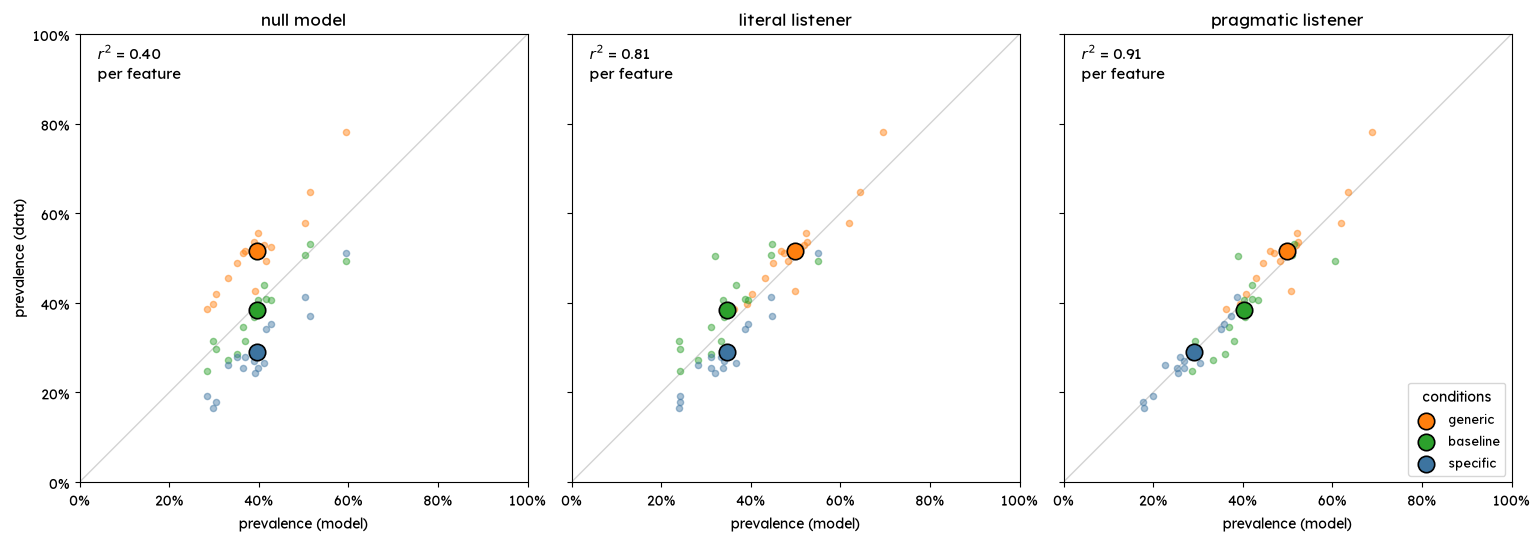

saved results/study6-ablations-zoib/ablations-flat-ls.png


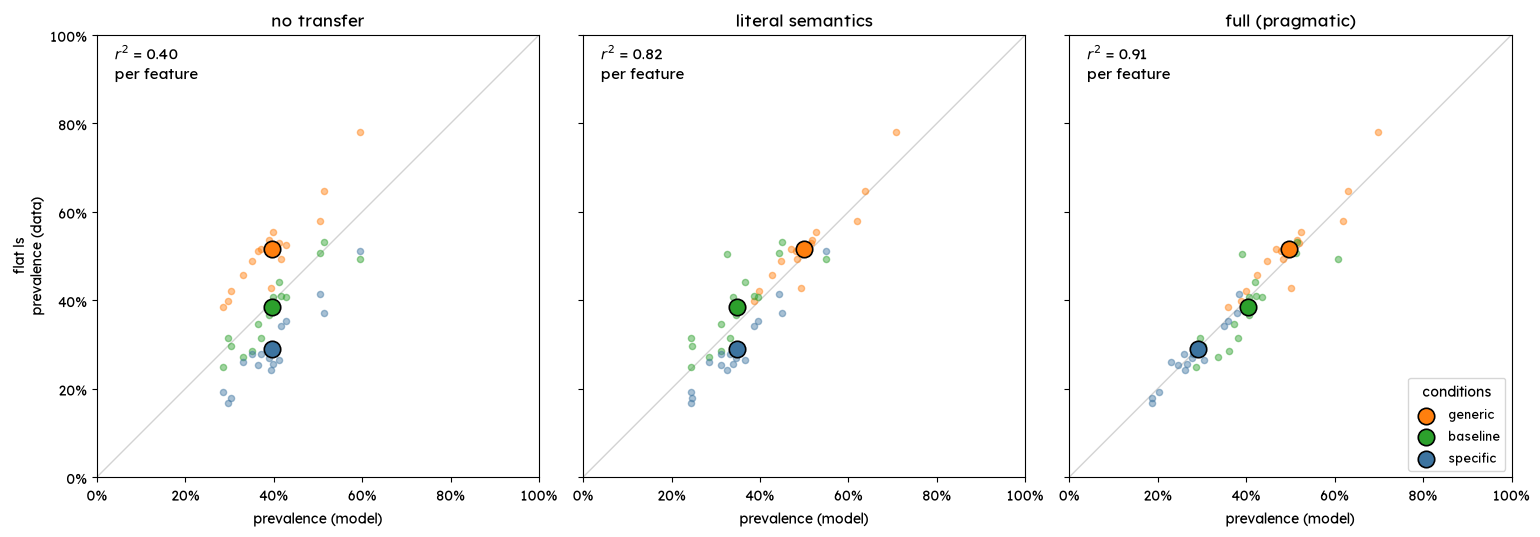

saved results/study6-ablations-zoib/ablations-fitted-vs-flat-ls.png


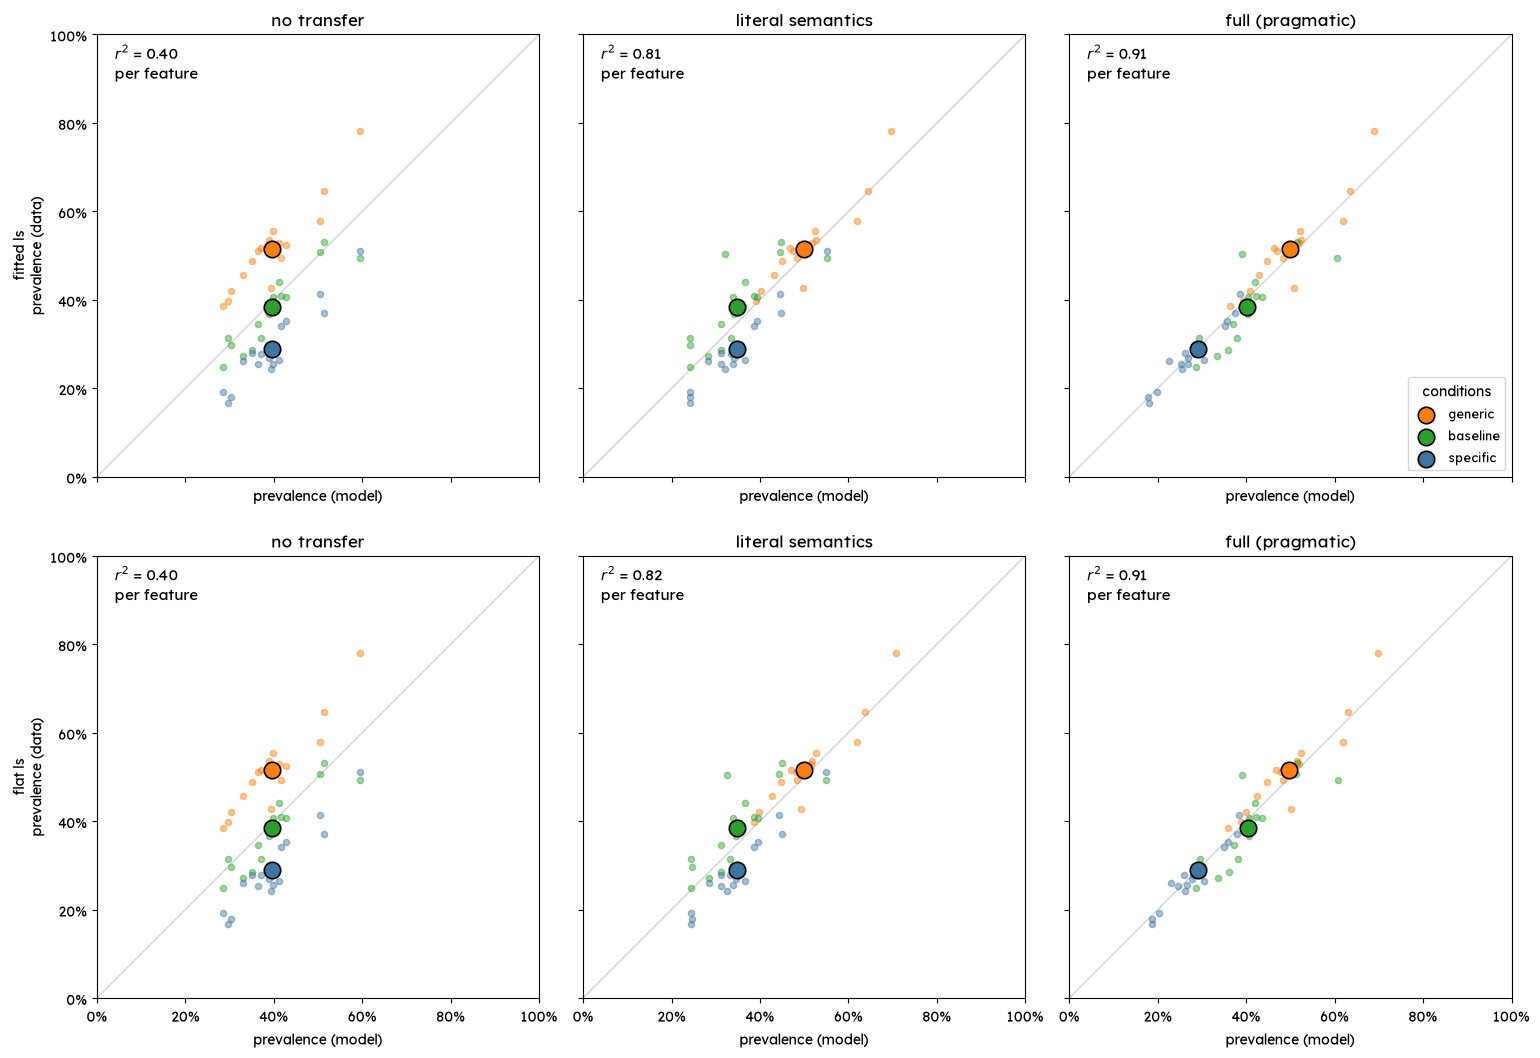

In [3]:
COND_ORDER = ['generic', 'baseline', 'specific']
COND_COLOR = {'generic': 'tab:orange', 'baseline': 'tab:green', 'specific': '#3d74a0'}

def panel(ax, r, title):
    ax.plot([0, 1], [0, 1], color='lightgray', lw=1, zorder=0)
    for c in COND_ORDER:
        ax.scatter(r['pred'][c], emp_cond[c], s=20, color=COND_COLOR[c], alpha=0.45, zorder=2)
        ax.scatter(r['pred'][c].mean(), emp_cond[c].mean(), s=140, color=COND_COLOR[c],
                   edgecolor='k', linewidth=1.2, zorder=3, label=c)
    ax.text(0.04, 0.90, f"$r^2$ = {r['r2']:.2f}\nper feature", transform=ax.transAxes, fontsize=11)
    ticks = np.linspace(0, 1, 6)
    ax.set_xticks(ticks); ax.set_xticklabels([f'{t:.0%}' for t in ticks])
    ax.set_yticks(ticks); ax.set_yticklabels([f'{t:.0%}' for t in ticks])
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal')
    ax.set_xlabel('prevalence (model)'); ax.set_title(title)

def plot_family_rows(families, out_name, titles=None, family_ylabel=True):
    titles = titles or ABLATIONS
    fig, axes = plt.subplots(len(families), 3, figsize=(15.5, 5.4 * len(families)),
                             sharex=True, sharey=True, squeeze=False)
    for row, fam in enumerate(families):
        for col, ab in enumerate(ABLATIONS):
            panel(axes[row, col], results[fam, ab], titles[col])
        axes[row, 0].set_ylabel(f"{fam}\nprevalence (data)" if family_ylabel else 'prevalence (data)')
    axes[0, -1].legend(title='conditions', fontsize=9, loc='lower right')
    plt.tight_layout()
    out_png = os.path.join(ABL_DIR, out_name)
    fig.savefig(out_png, dpi=150, bbox_inches='tight')
    print('saved', out_png)
    plt.show()

plot_family_rows(['fitted ls'], 'ablations-fitted-ls.png',
                 titles=['null model', 'literal listener', 'pragmatic listener'], family_ylabel=False)
plot_family_rows(['flat ls'], 'ablations-flat-ls.png')
plot_family_rows(FAMILIES, 'ablations-fitted-vs-flat-ls.png')